# Notebook 06 — Module 6: Leakage prevention and robust evaluation
**Input:** everything from Notebooks 02–05 (features, targets, folds, `ml_checkpoints`, annotated expression).

## A leakage problem found in Notebook 05 — and fixed here
Notebook 05's permutation importance was dominated by `dist_nearest_type` (drop 0.41 vs 0.11 for composition). These features are **unbounded distances** to the nearest cell of each type. A value of 80 µm says "there is no epithelial cell within 80 µm", which describes the **50–100 µm ring the target is built from**. The Notebook 03 guard only checked radius-based features, so it missed this. The first part of this notebook proves it and replaces those features with **distances capped at 30 µm**, so *every* feature depends only on cells within 30 µm.

## What this notebook tests
| Block | Question |
|---|---|
| **0. Reach audit** | Which features depend on cells beyond 30 µm? Brute-force tests of the corrected features |
| **A. Feature-set ablation** | original vs strict spatial, r15 vs r30, composition-only, long-range probe, **expression-only**, **combined**, coordinates |
| **B. Random vs spatial CV** | How much do random splits inflate performance (coordinates, spatial features, expression)? |
| **C. Sensitivity** | buffer size (0–150 µm), block size (250–1000 µm) × partition seeds |
| **D. Target-definition sensitivity** | does the result survive moving the target ring away (75–125, 100–150 µm)? |
| **E. Boundary cells** | performance on the 10% lowest-margin cells vs the rest |

Final output: robust, auto-generated claims with confidence intervals and `reports/evaluation_report.md`.

In [2]:
!pip install -q anndata
import os, json, time, warnings, sys, importlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import anndata as ad
from scipy.spatial import cKDTree
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*bottleneck.*")
warnings.filterwarnings("ignore", message=".*X does not have valid feature names.*")
warnings.filterwarnings("ignore", message=".*y_pred contains classes not in y_true.*")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/spatial_ml_breast_cancer")
except ImportError:
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "./spatial_ml_breast_cancer"))

for sub in ["results/figures", "results/tables", "reports", "src/spatialml", "data/processed"]:
    (PROJECT_DIR / sub).mkdir(parents=True, exist_ok=True)
FIG_DIR, TAB_DIR, REP_DIR, PROC_DIR = (PROJECT_DIR / p for p in ["results/figures", "results/tables", "reports", "data/processed"])
CKPT6 = PROC_DIR / "eval_checkpoints"; CKPT6.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

CONFIG = json.load(open(PROJECT_DIR / "configs/config.json"))
SEED = CONFIG["seed"]; RNG = np.random.default_rng(SEED)
TD = CONFIG["target_design"]
CONFIG.setdefault("notebook06", {
    "cap_um": 30, "max_train_cells": 60000, "n_bootstrap": 1000,
    "buffers_um": [0, 50, 150], "block_sizes_um": [250, 500, 1000], "partition_seeds": [0, 1, 2],
    "alt_annuli_um": [[75, 125], [100, 150]], "annulus_chunk": 5000,
    "run_random_cv": True, "run_expression_nonmarker": True,
    "run_partition_sensitivity": True, "run_annulus_sensitivity": True,
})
N6 = CONFIG["notebook06"]

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
Mounted at /content/drive


In [3]:
SRC = r'''"""spatialml.evaluation - split builders and a generic cross-validation runner (Module 6)."""
import numpy as np
from . import neighborhood as nbh
from . import modeling as ml


def spatial_splits(xy, valid, fold, buffer_um, max_train=None, seed=0):
    """Block folds; training cells closer than buffer_um to any test cell are dropped. valid = cells with a target."""
    out = {}
    for f in sorted(np.unique(fold)):
        tr_m, te_m = nbh.buffered_train_mask(xy, fold, f, buffer_um)
        tr = np.where(tr_m & valid)[0]; te = np.where(te_m & valid)[0]
        if max_train and len(tr) > max_train:
            tr = np.sort(np.random.default_rng(seed + int(f)).choice(tr, max_train, replace=False))
        out[int(f)] = (tr, te)
    return out


def random_splits(valid, n_folds=5, max_train=None, seed=0):
    """Ordinary random K-fold over cells (NO spatial separation): used only to demonstrate leakage."""
    rng = np.random.default_rng(seed)
    idx = np.where(valid)[0]; rng.shuffle(idx)
    parts = np.array_split(idx, n_folds); out = {}
    for f, te in enumerate(parts):
        tr = np.concatenate([p for g, p in enumerate(parts) if g != f])
        if max_train and len(tr) > max_train:
            tr = np.sort(rng.choice(tr, max_train, replace=False))
        out[f] = (tr, np.sort(te))
    return out


def run_cv(X, y, splits, cols, kind, params, seed, K):
    """Out-of-fold class probabilities (n, K); NaN rows were never in a test fold."""
    proba = np.full((len(X), K), np.nan, np.float32)
    for f, (tr, te) in splits.items():
        m = ml.build_model(kind, cols, seed, params).fit(X.iloc[tr][cols], y[tr])
        pf = np.zeros((len(te), K), np.float32)
        pf[:, np.asarray(m.classes_, dtype=int)] = m.predict_proba(X.iloc[te][cols])
        proba[te] = pf
    return proba
'''

for f in ["neighborhood", "stats", "modeling"]:
    assert (PROJECT_DIR / f"src/spatialml/{f}.py").exists(), f"Run Notebooks 03-05 first (missing {f}.py)"
(PROJECT_DIR / "src/spatialml/evaluation.py").write_text(SRC)
(PROJECT_DIR / "src/spatialml/__init__.py").write_text("from .neighborhood import *\nfrom .stats import *\n")
sys.path.insert(0, str(PROJECT_DIR / "src"))
import spatialml.neighborhood as nbh, spatialml.modeling as ml, spatialml.evaluation as ev
for m_ in (nbh, ml, ev): importlib.reload(m_)
print("spatialml.evaluation written")

spatialml.evaluation written


## Part 1 — Load data, expression, and the Notebook 05 settings

In [4]:
pq = PROC_DIR / "features_cell_level.parquet"
T = pd.read_parquet(pq) if pq.exists() else pd.read_csv(PROC_DIR / "features_cell_level.csv.gz", index_col=0)
apq = PROC_DIR / "target_annulus_composition.parquet"
A = pd.read_parquet(apq) if apq.exists() else pd.read_csv(PROC_DIR / "target_annulus_composition.csv.gz", index_col=0)
assert T.index.equals(A.index)
groups_json = json.load(open(REP_DIR / "feature_groups.json"))
TYPES = ["Epithelial", "T_cell", "B_cell", "Myeloid", "Mast_cell", "Endothelial", "Mural", "Stromal"]; ALL_TYPES = TYPES + ["Unassigned"]
for t in ALL_TYPES: T[f"type_{t}"] = (T["cell_type"] == t).astype(np.float32)
TYPE_COLS = [f"type_{t}" for t in ALL_TYPES]
SPATIAL = [f for f in groups_json["spatial_only"] if T[f].notna().any()]

valid = T["target_valid"].astype(bool).to_numpy(); vi = np.where(valid)[0]
xy = T[["x", "y"]].to_numpy(np.float64); fold = T["cv_fold"].to_numpy()
CLASSES = sorted(T.loc[valid, "microenvironment_class"].unique()); K = len(CLASSES)
y = np.where(valid, T["microenvironment_class"].map({c: i for i, c in enumerate(CLASSES)}).fillna(-1).astype(int), -1)
blk_all = pd.factorize(T["spatial_block"])[0]
low_margin = A["target_low_margin"].to_numpy().astype(bool)

# Hyper-parameters chosen by nested spatial CV in Notebook 05 (reused; not re-tuned on test folds)
pj = PROC_DIR / "ml_checkpoints/hgb_params_fold0.json"
HGB_P = json.load(open(pj))["params"] if pj.exists() else CONFIG["notebook05"]["hgb_grid"][0]
print("HGB parameters:", HGB_P)

# Expression: the cell's own log-normalised expression, aligned to the feature table.
# Read ONLY the expression layer and the cell/gene names straight from the HDF5 file. This avoids parsing obs/var DataFrames, so it
# works whatever pandas/anndata versions wrote the file (the "StringDtype ... na_value" error comes from that mismatch).
import h5py
try:
    from anndata.io import read_elem                  # anndata >= 0.11
except ImportError:
    from anndata.experimental import read_elem        # older anndata

def _names(f, group):
    g = f[group]; key = g.attrs.get("_index", "_index")
    key = key.decode() if isinstance(key, bytes) else key
    d = g[key]
    if isinstance(d, h5py.Group): d = d["values"]     # nullable-string encoding
    return [v.decode() if isinstance(v, bytes) else str(v) for v in d[:]]

with h5py.File(PROC_DIR / "xenium_breast_annotated.h5ad", "r") as f:
    obs_names = _names(f, "obs"); genes = _names(f, "var")
    Xe = read_elem(f["layers/lognorm"])
assert obs_names == [str(i) for i in T.index], "expression and feature table are misaligned"
Xe = Xe.toarray() if hasattr(Xe, "toarray") else np.asarray(Xe)
print(f"pandas {pd.__version__} | anndata {ad.__version__} | expression matrix {Xe.shape}")
EXPR = [f"expr_{g}" for g in genes]
ma = pd.read_csv(TAB_DIR / "marker_panel_audit.csv")
marker_genes = {g.strip() for s in ma.loc[ma["used"], "present"].dropna() for g in s.split(",")}
EXPR_NM = [f"expr_{g}" for g in genes if g not in marker_genes]
print(f"expression genes: {len(EXPR)} | marker genes used to build labels: {len(marker_genes)} | non-marker genes: {len(EXPR_NM)}")

HGB parameters: {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'max_iter': 200, 'l2_regularization': 1.0, 'min_samples_leaf': 100}
pandas 2.2.3 | anndata 0.13.4 | expression matrix (164000, 313)
expression genes: 313 | marker genes used to build labels: 60 | non-marker genes: 253


## Part 2 — Reach audit: which features depend on cells beyond 30 µm?
A feature is **leakage-safe by reach** if its value would be identical had every cell farther than the cap been deleted. Composition, density, diversity and edge features are bounded by their radius. Unbounded nearest-type distances are not.

feature,pct_cells_beyond_cap,pct_beyond_50um,median_um,p90_um
dist_nearest_Epithelial,37.3,29.6,14.2,148.8
dist_nearest_T_cell,42.2,21.5,24.5,71.0
dist_nearest_B_cell,80.4,70.2,101.8,281.1
dist_nearest_Myeloid,41.4,16.7,25.6,60.3
dist_nearest_Mast_cell,95.3,88.2,134.6,283.9
dist_nearest_Endothelial,62.1,35.8,38.3,99.4
dist_nearest_Mural,62.6,40.9,40.9,104.1
dist_nearest_Stromal,39.1,20.2,23.8,75.1


Nearest-type distances exceed 30 µm for 37-95% of cells -> for those cells the value is determined by cells farther than 30 µm, reaching into (and beyond) the 50-100 µm target ring.


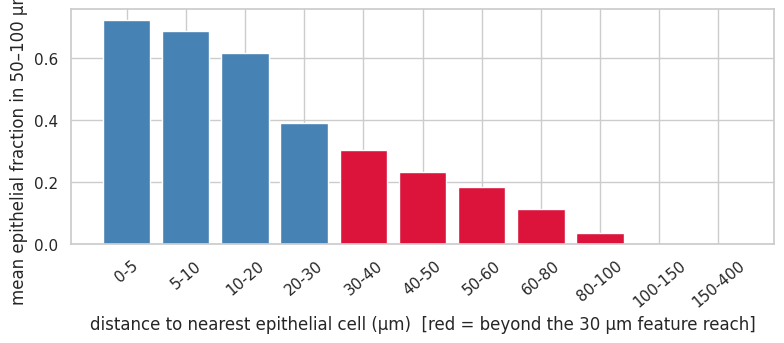

In [8]:
from IPython.display import HTML, display
cap = N6["cap_um"]; assert cap <= TD["target_annulus_um"][0] - 20, "cap should stay clearly below the target ring"
dist_cols = [c for c in SPATIAL if c.startswith("dist_nearest_")]
knn_cols = [c for c in SPATIAL if c.startswith("knn_dist_")]

audit = pd.DataFrame({"feature": dist_cols,
                      "pct_cells_beyond_cap": [(T[c] > cap).mean() * 100 for c in dist_cols],
                      "pct_beyond_50um": [(T[c] > TD["target_annulus_um"][0]).mean() * 100 for c in dist_cols],
                      "median_um": [T[c].median() for c in dist_cols], "p90_um": [T[c].quantile(.9) for c in dist_cols]})

# Safely construct an HTML table manually without calling pandas' internal formatting modules
audit_round = audit.round(1)
html_table = "<table border='1'><thead><tr>" + "".join(f"<th>{col}</th>" for col in audit_round.columns) + "</tr></thead><tbody>"
for row in audit_round.itertuples(index=False):
    html_table += "<tr>" + "".join(f"<td>{val}</td>" for val in row) + "</tr>"
html_table += "</tbody></table>"
display(HTML(html_table))

audit.round(3).to_csv(TAB_DIR / "reach_audit_distance_features.csv", index=False)
print(f"Nearest-type distances exceed {cap} µm for {audit['pct_cells_beyond_cap'].min():.0f}-{audit['pct_cells_beyond_cap'].max():.0f}% of cells "
      f"-> for those cells the value is determined by cells farther than {cap} µm, reaching into (and beyond) the {TD['target_annulus_um'][0]}-{TD['target_annulus_um'][1]} µm target ring.")

# How strongly does the long-range distance encode the target ring's composition?
d = T["dist_nearest_Epithelial"].to_numpy(); fe = A["ann_frac_Epithelial"].to_numpy()
bins = np.array([0, 5, 10, 20, 30, 40, 50, 60, 80, 100, 150, 400]); bi = np.digitize(np.minimum(d, bins[-1] - 1e-6), bins) - 1
curve = pd.DataFrame({"d": d, "fe": fe, "b": bi})[valid].groupby("b").agg(mean_epi=("fe", "mean"), n=("fe", "size"))
curve.index = [f"{bins[i]}-{bins[i+1]}" for i in curve.index]
fig, ax = plt.subplots(figsize=(8, 3.6)); ax.bar(curve.index, curve["mean_epi"], color=["steelblue"] * 4 + ["crimson"] * (len(curve) - 4))
ax.set_xlabel("distance to nearest epithelial cell (µm)  [red = beyond the 30 µm feature reach]"); ax.set_ylabel("mean epithelial fraction in 50–100 µm ring")
plt.xticks(rotation=40); plt.tight_layout(); fig.savefig(FIG_DIR / "reach_audit_distance_vs_target.png", dpi=200); plt.show()

In [9]:
# ---- Strict (reach <= cap) features ----
tree = cKDTree(xy)
Xs = pd.DataFrame(index=T.index)
CAPD = [f"{c}_cap{cap}" for c in dist_cols]
for c, n_ in zip(dist_cols, CAPD): Xs[n_] = np.minimum(T[c].to_numpy(), cap).astype(np.float32)
dk, _ = tree.query(xy, k=11, workers=-1); dkc = np.minimum(dk[:, 1:], cap)      # cap EACH neighbour distance, then average
KNNC = []
for k in (5, 10):
    Xs[f"knn_dist_cap{cap}_k{k}"] = dkc[:, :k].mean(1).astype(np.float32); KNNC.append(f"knn_dist_cap{cap}_k{k}")
BASE = [c for c in SPATIAL if c not in dist_cols and c not in knn_cols]
STRICT = BASE + CAPD + KNNC

# ---- Reach test: recompute capped features using ONLY cells within `cap` µm, compare with the stored columns ----
samp = RNG.choice(vi, 150, replace=False); codes_t = T["cell_type"].to_numpy()
for i in samp:
    dd = np.hypot(xy[:, 0] - xy[i, 0], xy[:, 1] - xy[i, 1]); near = (dd <= cap); near[i] = False
    for t in [t_ for t_ in TYPES if f"dist_nearest_{t_}_cap{cap}" in Xs.columns]:
        m = near & (codes_t == t); ref = dd[m].min() if m.any() else cap
        assert np.isclose(Xs.iloc[i][f"dist_nearest_{t}_cap{cap}"], ref, atol=1e-3), (i, t)
    loc = np.sort(dd[near])[:10]; loc = np.concatenate([loc, np.full(10 - len(loc), cap)])
    assert np.isclose(Xs.iloc[i][f"knn_dist_cap{cap}_k10"], loc.mean(), atol=1e-3), i
print(f"PASS: capped distance features computed from cells within {cap} µm only match the stored values (150 random cells).")
r_max = max(TD["feature_neighborhood_radii_um"]); assert r_max <= cap
print(f"All {len(STRICT)} strict features depend only on cells within {cap} µm; target ring starts at {TD['target_annulus_um'][0]} µm (gap {TD['target_annulus_um'][0]-cap} µm).")

FORBIDDEN = ("ann_", "target", "microenvironment", "cv_fold", "spatial_block", "cell_id")
assert not [c for c in STRICT + EXPR if c.startswith(FORBIDDEN)]

# ---- Assemble one float32 matrix for all experiments ----
X6 = pd.concat([T[sorted(set(SPATIAL + TYPE_COLS + ["x", "y"]))].astype(np.float32), Xs,
                pd.DataFrame(Xe.astype(np.float32), index=T.index, columns=EXPR)], axis=1)
del Xe
SETS = {
    "spatial_original": SPATIAL,
    "spatial_strict": STRICT,
    "strict_r15_only": [c for c in STRICT if c.endswith("_r15")],
    "strict_r30_only": [c for c in STRICT if not c.endswith("_r15")],
    "strict_composition": [c for c in STRICT if c.startswith("frac_")],
    "long_range_probe": dist_cols + knn_cols,
    "expression": EXPR, "expression_nonmarker": EXPR_NM,
    "combined": STRICT + EXPR, "coordinates": ["x", "y"],
}
print({k: len(v) for k, v in SETS.items()}); print("X6:", X6.shape, f"{X6.memory_usage().sum()/1e9:.2f} GB")

PASS: capped distance features computed from cells within 30 µm only match the stored values (150 random cells).
All 40 strict features depend only on cells within 30 µm; target ring starts at 50 µm (gap 20 µm).
{'spatial_original': 40, 'spatial_strict': 40, 'strict_r15_only': 15, 'strict_r30_only': 25, 'strict_composition': 18, 'long_range_probe': 10, 'expression': 313, 'expression_nonmarker': 253, 'combined': 353, 'coordinates': 2}
X6: (164000, 374) 0.25 GB


## Part 3 — Experiment runner (spatial CV, checkpointed)
Every experiment uses the same 5 spatial block folds as Notebook 05 with a 100 µm buffer (`spatial_original` is re-run here with identical settings so comparisons are exact). Results are saved to Drive after each experiment, so a Colab disconnect resumes where it stopped.

In [10]:
RES = {}
def run_exp(name, cols, splits, kind="hgb", params=None):
    ck = CKPT6 / f"{name}.npz"
    if ck.exists():
        RES[name] = np.load(ck)["proba"]; print(f"[{name}] loaded from checkpoint"); return
    t0 = time.time()
    p = ev.run_cv(X6, y, splits, cols, kind, params if params is not None else HGB_P, SEED, K)
    np.savez_compressed(ck, proba=p); RES[name] = p
    print(f"[{name}] {len(cols)} features, {(time.time()-t0)/60:.1f} min")

SPL = ev.spatial_splits(xy, valid, fold, TD["spatial_cv_buffer_um"], N6["max_train_cells"], SEED)

run_exp("A__type_lookup", TYPE_COLS, SPL, kind="lookup", params={"type_cols": TYPE_COLS})
for nm in ["spatial_original", "spatial_strict", "strict_r15_only", "strict_r30_only", "strict_composition", "long_range_probe", "coordinates"]:
    run_exp(f"A__{nm}", SETS[nm], SPL)
run_exp("A__expression", SETS["expression"], SPL)
if N6["run_expression_nonmarker"]: run_exp("A__expression_nonmarker", SETS["expression_nonmarker"], SPL)
run_exp("A__combined", SETS["combined"], SPL)

[A__type_lookup] 9 features, 0.0 min
[A__spatial_original] 40 features, 1.2 min
[A__spatial_strict] 40 features, 1.1 min
[A__strict_r15_only] 15 features, 0.6 min
[A__strict_r30_only] 25 features, 0.8 min
[A__strict_composition] 18 features, 0.7 min
[A__long_range_probe] 10 features, 0.5 min
[A__coordinates] 2 features, 0.3 min
[A__expression] 313 features, 7.8 min
[A__expression_nonmarker] 253 features, 6.2 min
[A__combined] 353 features, 8.6 min


## Part 4 — Block A results: what survives leakage control?
Block-bootstrap CIs resample 500 µm tissue blocks. Differences are **paired** (same resampled blocks).

experiment,n_features,balanced_accuracy,ci_low,ci_high,macro_f1
spatial_original,40,0.8329,0.8183,0.8458,0.833
long_range_probe,10,0.8253,0.8105,0.8385,0.8256
combined,353,0.7731,0.7594,0.7851,0.7686
strict_composition,18,0.746,0.7334,0.7564,0.7392
spatial_strict,40,0.7457,0.7332,0.7563,0.7393
strict_r30_only,25,0.7449,0.7322,0.7558,0.7384
expression,313,0.7313,0.717,0.7452,0.7245
expression_nonmarker,253,0.7108,0.6967,0.7245,0.7027
strict_r15_only,15,0.6689,0.658,0.6781,0.6496
type_lookup,9,0.6122,0.6024,0.6207,0.5629


A,B,diff_bal_acc,ci_low,ci_high,excludes_zero
spatial_strict,spatial_original,-0.0872,-0.0981,-0.0772,True
spatial_strict,type_lookup,0.1335,0.1241,0.1426,True
expression,type_lookup,0.1191,0.1083,0.1309,True
spatial_strict,expression,0.0144,0.0043,0.024,True
combined,expression,0.0418,0.0353,0.0489,True
combined,spatial_strict,0.0274,0.0225,0.0325,True
expression_nonmarker,type_lookup,0.0986,0.0879,0.11,True
strict_composition,spatial_strict,0.0002,-0.0018,0.0025,False
strict_r30_only,strict_r15_only,0.0759,0.0705,0.0816,True


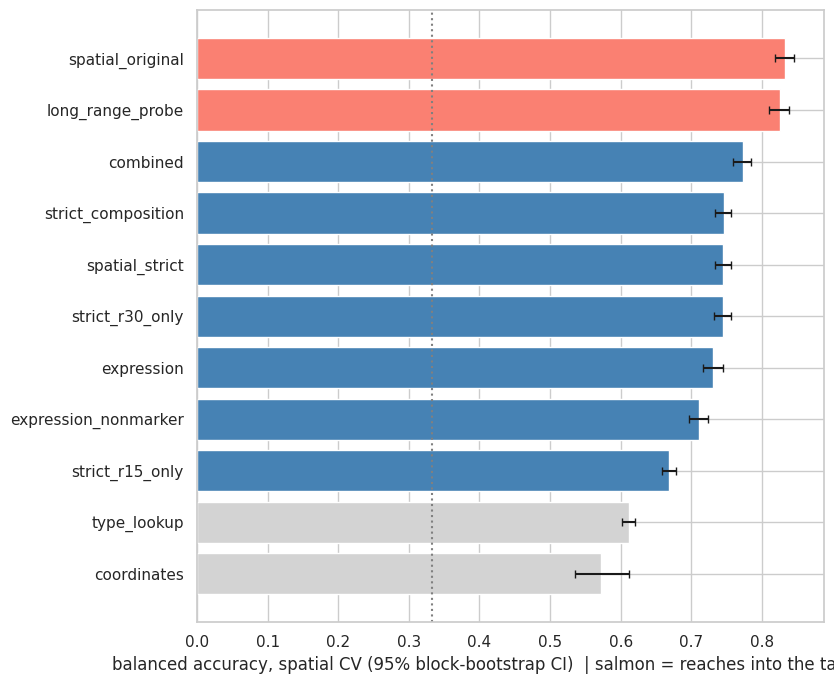

In [14]:
from sklearn.metrics import balanced_accuracy_score
from IPython.display import HTML, display
codes_v, uni_v = pd.factorize(blk_all[vi]); nb = len(uni_v)
W = ml.bootstrap_weights(nb, N6["n_bootstrap"], RNG)
ci = lambda a: np.nanpercentile(a, [2.5, 97.5])

def evaluate(proba, y_=None, idx=None, W_=None, blocks=None):
    y_ = y if y_ is None else y_; idx = vi if idx is None else idx
    if blocks is None: codes, uni = (codes_v, uni_v) if idx is vi else pd.factorize(blk_all[idx])
    else: codes, uni = blocks
    nb_ = len(uni); pred = np.nan_to_num(proba[idx]).argmax(1)
    Cb = ml.block_confusions(y_[idx], pred, codes, nb_, K)
    W_ = W if (W_ is None and nb_ == nb and idx is vi) else (W_ if W_ is not None else ml.bootstrap_weights(nb_, N6["n_bootstrap"], RNG))
    return ml.metrics_from_counts(Cb.sum(0)), ml.metrics_from_counts(np.einsum("rb,bkl->rkl", W_, Cb))

ABL = ["A__type_lookup", "A__coordinates", "A__long_range_probe", "A__spatial_original", "A__spatial_strict", "A__strict_r15_only",
       "A__strict_r30_only", "A__strict_composition", "A__expression", "A__expression_nonmarker", "A__combined"]
ABL = [a for a in ABL if a in RES]
PT, BT = {}, {}
for n in ABL: PT[n], BT[n] = evaluate(RES[n])
rows = [{"experiment": n.replace("A__", ""), "n_features": len(SETS.get(n.replace("A__", ""), TYPE_COLS)),
         "balanced_accuracy": float(PT[n]["balanced_accuracy"]), "ci_low": ci(BT[n]["balanced_accuracy"])[0], "ci_high": ci(BT[n]["balanced_accuracy"])[1],
         "macro_f1": float(PT[n]["macro_f1"])} for n in ABL]
TA = pd.DataFrame(rows).sort_values("balanced_accuracy", ascending=False)

# Safe display of TA
ta_round = TA.round(4)
html_ta = "<table border='1'><thead><tr>" + "".join(f"<th>{c}</th>" for c in ta_round.columns) + "</tr></thead><tbody>"
for r in ta_round.itertuples(index=False):
    html_ta += "<tr>" + "".join(f"<td>{v}</td>" for v in r) + "</tr>"
html_ta += "</tbody></table>"
display(HTML(html_ta))
TA.round(5).to_csv(TAB_DIR / "eval_feature_set_ablation.csv", index=False)

pairs = [("A__spatial_strict", "A__spatial_original"), ("A__spatial_strict", "A__type_lookup"), ("A__expression", "A__type_lookup"),
         ("A__spatial_strict", "A__expression"), ("A__combined", "A__expression"), ("A__combined", "A__spatial_strict"),
         ("A__expression_nonmarker", "A__type_lookup"), ("A__strict_composition", "A__spatial_strict"), ("A__strict_r30_only", "A__strict_r15_only")]
rows = []
for a, b in pairs:
    if a in PT and b in PT:
        dlt = BT[a]["balanced_accuracy"] - BT[b]["balanced_accuracy"]; lo, hi = ci(dlt)
        rows.append({"A": a.replace("A__", ""), "B": b.replace("A__", ""), "diff_bal_acc": float(PT[a]["balanced_accuracy"] - PT[b]["balanced_accuracy"]),
                     "ci_low": lo, "ci_high": hi, "excludes_zero": bool(lo > 0 or hi < 0)})
PA = pd.DataFrame(rows)

# Safe display of PA
pa_round = PA.round(4)
html_pa = "<table border='1'><thead><tr>" + "".join(f"<th>{c}</th>" for c in pa_round.columns) + "</tr></thead><tbody>"
for r in pa_round.itertuples(index=False):
    html_pa += "<tr>" + "".join(f"<td>{v}</td>" for v in r) + "</tr>"
html_pa += "</tbody></table>"
display(HTML(html_pa))
PA.round(5).to_csv(TAB_DIR / "eval_paired_contrasts.csv", index=False)

fig, ax = plt.subplots(figsize=(8.5, 0.5 * len(TA) + 1.5)); s = TA.iloc[::-1]
colr = {"type_lookup": "lightgrey", "coordinates": "lightgrey", "long_range_probe": "salmon", "spatial_original": "salmon"}
ax.barh(s["experiment"], s["balanced_accuracy"], xerr=[s["balanced_accuracy"] - s["ci_low"], s["ci_high"] - s["balanced_accuracy"]],
        color=[colr.get(e, "steelblue") for e in s["experiment"]], ecolor="k", capsize=3)
ax.axvline(1 / K, color="grey", ls=":"); ax.set_xlabel("balanced accuracy, spatial CV (95% block-bootstrap CI)  | salmon = reaches into the target ring")
plt.tight_layout(); fig.savefig(FIG_DIR / "eval_feature_set_ablation.png", dpi=200); plt.show()

## Part 5 — Block B: how much do random splits inflate performance?
Random K-fold puts neighboring cells in both train and test sets. A model that only knows `(x, y)` can then look excellent. We run the same models under random and spatial CV; the **gap** measures how easily each feature set exploits spatial autocorrelation.

[B__random__coordinates] loaded from checkpoint
[B__random__spatial_strict] loaded from checkpoint
[B__random__expression] loaded from checkpoint


features,random_cv,spatial_cv,inflation,inflation_ci_low,inflation_ci_high
coordinates,0.8575,0.572,0.2856,0.2492,0.3225
spatial_strict,0.7619,0.7457,0.0161,0.0131,0.0197
expression,0.7432,0.7313,0.0118,0.0082,0.0158


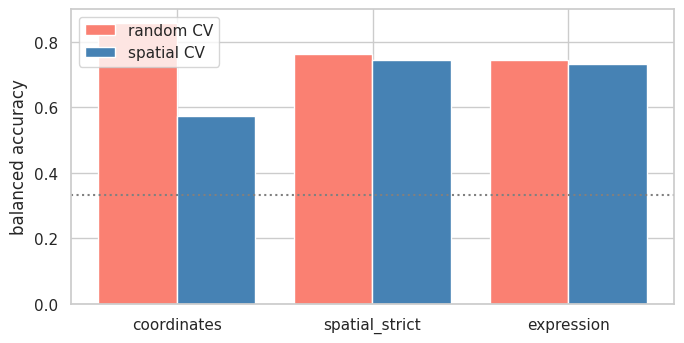

In [16]:
if N6["run_random_cv"]:
    RSPL = ev.random_splits(valid, 5, N6["max_train_cells"], SEED)
    run_exp("B__random__coordinates", SETS["coordinates"], RSPL)
    run_exp("B__random__spatial_strict", SETS["spatial_strict"], RSPL)
    run_exp("B__random__expression", SETS["expression"], RSPL)
    rows = []
    for nm in ["coordinates", "spatial_strict", "expression"]:
        pr, br = evaluate(RES[f"B__random__{nm}"]); ps, bs = PT[f"A__{nm}"], BT[f"A__{nm}"]
        rows.append({"features": nm, "random_cv": float(pr["balanced_accuracy"]), "spatial_cv": float(ps["balanced_accuracy"]),
                     "inflation": float(pr["balanced_accuracy"] - ps["balanced_accuracy"]),
                     "inflation_ci_low": ci(br["balanced_accuracy" ] - bs["balanced_accuracy"])[0], "inflation_ci_high": ci(br["balanced_accuracy"] - bs["balanced_accuracy"])[1]})
    TB = pd.DataFrame(rows)

    # Safe display of TB bypassing Colab's pandas format_name bug
    tb_round = TB.round(4)
    html_tb = "<table border='1'><thead><tr>" + "".join(f"<th>{c}</th>" for c in tb_round.columns) + "</tr></thead><tbody>"
    for r in tb_round.itertuples(index=False):
        html_tb += "<tr>" + "".join(f"<td>{v}</td>" for v in r) + "</tr>"
    html_tb += "</tbody></table>"
    display(HTML(html_tb))

    TB.round(5).to_csv(TAB_DIR / "eval_random_vs_spatial_cv.csv", index=False)
    fig, ax = plt.subplots(figsize=(7, 3.6)); x_ = np.arange(len(TB)); ax.bar(x_ - .2, TB["random_cv"], .4, label="random CV", color="salmon"); ax.bar(x_ + .2, TB["spatial_cv"], .4, label="spatial CV", color="steelblue")
    ax.set_xticks(x_); ax.set_xticklabels(TB["features"]); ax.axhline(1 / K, color="grey", ls=":"); ax.set_ylabel("balanced accuracy"); ax.legend()
    plt.tight_layout(); fig.savefig(FIG_DIR / "eval_random_vs_spatial_cv.png", dpi=200); plt.show()

## Part 6 — Block C: sensitivity to the buffer, the block size and the partition seed

[C__buffer0__spatial_strict] loaded from checkpoint
[C__buffer50__spatial_strict] loaded from checkpoint
[C__buffer150__spatial_strict] loaded from checkpoint


buffer_um,balanced_accuracy,ci_low,ci_high
0,0.7484,0.7363,0.759
50,0.747,0.7347,0.758
100,0.7457,0.7332,0.7563
150,0.7449,0.7324,0.7554


[C__block250_seed0__spatial_strict] loaded from checkpoint
[C__block250_seed1__spatial_strict] loaded from checkpoint
[C__block250_seed2__spatial_strict] loaded from checkpoint
[C__block500_seed0__spatial_strict] loaded from checkpoint
[C__block500_seed1__spatial_strict] loaded from checkpoint
[C__block500_seed2__spatial_strict] loaded from checkpoint
[C__block1000_seed0__spatial_strict] loaded from checkpoint
[C__block1000_seed1__spatial_strict] loaded from checkpoint
[C__block1000_seed2__spatial_strict] loaded from checkpoint


block_um,mean,std,min,max
250,0.7479,0.0007,0.7471,0.7485
500,0.7461,0.0001,0.746,0.7463
1000,0.7472,0.0,0.7472,0.7472


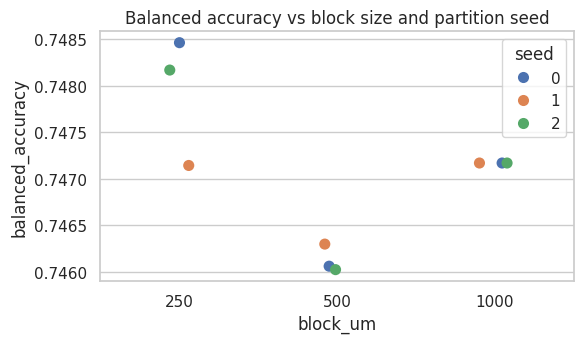

In [18]:
from IPython.display import HTML, display

for b in N6["buffers_um"]:
    run_exp(f"C__buffer{b}__spatial_strict", SETS["spatial_strict"], ev.spatial_splits(xy, valid, fold, b, N6["max_train_cells"], SEED))
rows = []
for b in sorted(set(N6["buffers_um"] + [TD["spatial_cv_buffer_um"]])):
    nm = "A__spatial_strict" if b == TD["spatial_cv_buffer_um"] else f"C__buffer{b}__spatial_strict"
    p_, b_ = evaluate(RES[nm]); rows.append({"buffer_um": b, "balanced_accuracy": float(p_["balanced_accuracy"]), "ci_low": ci(b_["balanced_accuracy"])[0], "ci_high": ci(b_["balanced_accuracy"])[1]})
TC1 = pd.DataFrame(rows)

# Safe display of TC1
tc1_round = TC1.round(4)
html_tc1 = "<table border='1'><thead><tr>" + "".join(f"<th>{col}</th>" for col in tc1_round.columns) + "</tr></thead><tbody>"
for row in tc1_round.itertuples(index=False):
    html_tc1 += "<tr>" + "".join(f"<td>{val}</td>" for val in row) + "</tr>"
html_tc1 += "</tbody></table>"
display(HTML(html_tc1))

TC1.round(5).to_csv(TAB_DIR / "eval_buffer_sensitivity.csv", index=False)

if N6["run_partition_sensitivity"]:
    rows = []
    for bs_ in N6["block_sizes_um"]:
        for sd in N6["partition_seeds"]:
            _, f_ = nbh.make_spatial_folds(xy, bs_, CONFIG["notebook03"]["spatial_cv_folds"], seed=sd)
            nm = f"C__block{bs_}_seed{sd}__spatial_strict"
            run_exp(nm, SETS["spatial_strict"], ev.spatial_splits(xy, valid, f_, TD["spatial_cv_buffer_um"], N6["max_train_cells"], SEED))
            p_, b_ = evaluate(RES[nm]); rows.append({"block_um": bs_, "seed": sd, "balanced_accuracy": float(p_["balanced_accuracy"])})
    TC2 = pd.DataFrame(rows); TC2.round(5).to_csv(TAB_DIR / "eval_partition_sensitivity.csv", index=False)

    summ = TC2.groupby("block_um")["balanced_accuracy"].agg(["mean", "std", "min", "max"])

    # Safe display of summ
    summ_round = summ.round(4).reset_index()
    html_summ = "<table border='1'><thead><tr>" + "".join(f"<th>{col}</th>" for col in summ_round.columns) + "</tr></thead><tbody>"
    for row in summ_round.itertuples(index=False):
        html_summ += "<tr>" + "".join(f"<td>{val}</td>" for val in row) + "</tr>"
    html_summ += "</tbody></table>"
    display(HTML(html_summ))

    fig, ax = plt.subplots(figsize=(6, 3.6)); sns.stripplot(data=TC2, x="block_um", y="balanced_accuracy", hue="seed", ax=ax, size=8, palette="deep")
    ax.set_title("Balanced accuracy vs block size and partition seed"); plt.tight_layout(); fig.savefig(FIG_DIR / "eval_partition_sensitivity.png", dpi=200); plt.show()

## Part 7 — Block D: does the result survive moving the target ring away from the cell?
If features leaked through overlap, accuracy would collapse as the target ring moves outward. If the structure is real, accuracy should **decay smoothly** (tissue regions are spatially coherent) but stay well above the own-type baseline. For each alternative ring we rebuild the 3-class target (k-means on Hellinger-transformed composition) and use a buffer equal to the ring's outer radius.

loaded annulus statistics from checkpoint


ring_um,n_valid,ARI_vs_primary,type_lookup,strict,strict_ci_low,strict_ci_high,original
50-100,163122,1.0,0.6122,0.7457,0.7332,0.7563,0.8329
75-125,163647,0.7089,0.5665,0.7146,0.702,0.7268,0.7978
100-150,163851,0.5375,0.5283,0.688,0.6736,0.7028,0.7567


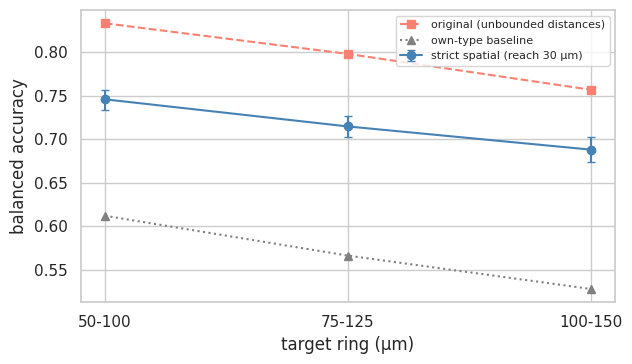

In [20]:
from IPython.display import HTML, display

if N6["run_annulus_sensitivity"]:
    codes_all = T["cell_type"].map({t: i for i, t in enumerate(ALL_TYPES)}).to_numpy()
    onehot = np.eye(len(ALL_TYPES), dtype=np.float32)[codes_all]
    alts = [tuple(a) for a in N6["alt_annuli_um"]]
    ack = CKPT6 / "annulus_alt_counts.npz"
    if ack.exists():
        z = np.load(ack); alt_stats = {a: (z[f"c{i}"], z[f"n{i}"]) for i, a in enumerate(alts)}; print("loaded annulus statistics from checkpoint")
    else:
        t0 = time.time(); st_ = nbh.ring_stats(xy, onehot, alts, chunk=N6["annulus_chunk"])
        alt_stats = {a: (st_[a]["counts"], st_[a]["n"]) for a in alts}
        np.savez_compressed(ack, **{f"{k}{i}": v[j] for i, (a, v) in enumerate(alt_stats.items()) for k, j in (("c", 0), ("n", 1))}); print(f"ring statistics: {(time.time()-t0)/60:.1f} min")

    rows = []
    # reference row: the primary ring
    p0, b0 = PT["A__spatial_strict"], BT["A__spatial_strict"]; po, bo = PT["A__spatial_original"], BT["A__spatial_original"]; pl = PT["A__type_lookup"]
    rows.append({"ring_um": f"{TD["target_annulus_um"][0]}-{TD["target_annulus_um"][1]}", "n_valid": int(valid.sum()), "ARI_vs_primary": 1.0,
                 "type_lookup": float(pl["balanced_accuracy"]), "strict": float(p0["balanced_accuracy"]), "strict_ci_low": ci(b0["balanced_accuracy"])[0], "strict_ci_high": ci(b0["balanced_accuracy"])[1],
                 "original": float(po["balanced_accuracy"])})
    for a in alts:
        cnt, n_ = alt_stats[a]; asg = cnt[:, :-1].sum(1); va = (n_ >= TD["min_cells_in_annulus"]) & (asg >= TD["min_cells_in_annulus"])
        with np.errstate(divide="ignore", invalid="ignore"): H = np.sqrt(np.nan_to_num(cnt[:, :-1] / asg[:, None]))
        km = KMeans(K, n_init=5, random_state=SEED).fit(H[va]); ya = np.full(len(T), -1); ya[va] = km.labels_
        both = va & valid; ari = adjusted_rand_score(ya[both], y[both])
        via = np.where(va)[0]; spl = ev.spatial_splits(xy, va, fold, int(a[1]), N6["max_train_cells"], SEED)
        tag = f"{a[0]}_{a[1]}"; out = {}
        for nm in ["spatial_strict", "spatial_original"]:
            ck = CKPT6 / f"D__ring{tag}__{nm}.npz"
            if ck.exists(): pr_ = np.load(ck)["proba"]
            else: pr_ = ev.run_cv(X6, ya, spl, SETS[nm], "hgb", HGB_P, SEED, K); np.savez_compressed(ck, proba=pr_)
            out[nm] = evaluate(pr_, ya, via)
        ckl = CKPT6 / f"D__ring{tag}__lookup.npz"
        if ckl.exists(): pl_ = np.load(ckl)["proba"]
        else: pl_ = ev.run_cv(X6, ya, spl, TYPE_COLS, "lookup", {"type_cols": TYPE_COLS}, SEED, K); np.savez_compressed(ckl, proba=pl_)
        lk = evaluate(pl_, ya, via)[0]
        rows.append({"ring_um": f"{a[0]}-{a[1]}", "n_valid": int(va.sum()), "ARI_vs_primary": ari, "type_lookup": float(lk["balanced_accuracy"]),
                     "strict": float(out["spatial_strict"][0]["balanced_accuracy"]), "strict_ci_low": ci(out["spatial_strict"][1]["balanced_accuracy"])[0],
                     "strict_ci_high": ci(out["spatial_strict"][1]["balanced_accuracy"])[1], "original": float(out["spatial_original"][0]["balanced_accuracy"])})
    TD_ = pd.DataFrame(rows)

    # Safe HTML display of TD_ bypassing Colab's pandas format_name bug
    td_round = TD_.round(4)
    html_td = "<table border='1'><thead><tr>" + "".join(f"<th>{col}</th>" for col in td_round.columns) + "</tr></thead><tbody>"
    for row in td_round.itertuples(index=False):
        html_td += "<tr>" + "".join(f"<td>{val}</td>" for val in row) + "</tr>"
    html_td += "</tbody></table>"
    display(HTML(html_td))

    TD_.round(5).to_csv(TAB_DIR / "eval_target_ring_sensitivity.csv", index=False)
    fig, ax = plt.subplots(figsize=(6.5, 3.8)); x_ = np.arange(len(TD_))
    ax.errorbar(x_, TD_["strict"], yerr=[TD_["strict"] - TD_["strict_ci_low"], TD_["strict_ci_high"] - TD_["strict"]], fmt="o-", label="strict spatial (reach 30 µm)", color="steelblue", capsize=3)
    ax.plot(x_, TD_["original"], "s--", color="salmon", label="original (unbounded distances)"); ax.plot(x_, TD_["type_lookup"], "^:", color="grey", label="own-type baseline")
    ax.set_xticks(x_); ax.set_xticklabels(TD_["ring_um"]); ax.set_xlabel("target ring (µm)"); ax.set_ylabel("balanced accuracy"); ax.legend(fontsize=8)
    plt.tight_layout(); fig.savefig(FIG_DIR / "eval_target_ring_sensitivity.png", dpi=200); plt.show()

## Part 8 — Block E: boundary cells and per-class behaviour

In [23]:
from IPython.display import HTML, display

rows = []
for n in ["A__type_lookup", "A__spatial_strict", "A__expression", "A__combined"]:
    if n not in RES: continue
    pr_ = np.nan_to_num(RES[n]).argmax(1); lm = low_margin[vi]
    rows.append({"model": n.replace("A__", ""), "all": balanced_accuracy_score(y[vi], pr_[vi]),
                 "high_margin_90pct": balanced_accuracy_score(y[vi][~lm], pr_[vi][~lm]), "low_margin_10pct": balanced_accuracy_score(y[vi][lm], pr_[vi][lm])})
TE = pd.DataFrame(rows)

# Safe HTML display of TE
te_round = TE.round(3)
html_te = "<table border='1'><thead><tr>" + "".join(f"<th>{col}</th>" for col in te_round.columns) + "</tr></thead><tbody>"
for row in te_round.itertuples(index=False):
    html_te += "<tr>" + "".join(f"<td>{val}</td>" for val in row) + "</tr>"
html_te += "</tbody></table>"
display(HTML(html_te))

TE.round(4).to_csv(TAB_DIR / "eval_boundary_analysis.csv", index=False)

rows = []
for n in ["A__type_lookup", "A__spatial_strict", "A__expression", "A__combined"]:
    if n not in PT: continue
    for k in range(K):
        lo, hi = ci(BT[n]["recall"][:, k]); rows.append({"model": n.replace("A__", ""), "class": CLASSES[k], "recall": PT[n]["recall"][k], "ci_low": lo, "ci_high": hi})
TF = pd.DataFrame(rows)

# Manual pivot in Python to completely bypass pandas.pivot / unstack
models = sorted(list({r["model"] for r in rows}))
classes = CLASSES
pivot_dict = {c: {m: "" for m in models} for c in classes}
for r in rows:
    pivot_dict[r["class"]][r["model"]] = f"{r['recall']:.3f}"

# Safe HTML display of the pivoted table
html_tf = "<table border='1'><thead><tr><th>class</th>" + "".join(f"<th>{m}</th>" for m in models) + "</tr></thead><tbody>"
for cl in classes:
    html_tf += f"<tr><td>{cl}</td>" + "".join(f"<td>{pivot_dict[cl][m]}</td>" for m in models) + "</tr>"
html_tf += "</tbody></table>"
display(HTML(html_tf))

TF.round(4).to_csv(TAB_DIR / "eval_per_class_recall.csv", index=False)

model,all,high_margin_90pct,low_margin_10pct
type_lookup,0.612,0.621,0.515
spatial_strict,0.746,0.767,0.556
expression,0.731,0.75,0.553
combined,0.773,0.796,0.565


class,combined,expression,spatial_strict,type_lookup
ME1_Epithelial-rich,0.856,0.829,0.844,0.782
ME2_Epithelial/T_cell,0.582,0.509,0.525,0.159
ME3_T_cell/Stromal,0.882,0.857,0.868,0.895


## Part 9 — Robust claims, evaluation report and saved outputs

In [24]:
def getd(a, b, df=PA):
    r = df[(df["A"] == a) & (df["B"] == b)]
    return None if r.empty else r.iloc[0]
def fmt(r): return "n/a" if r is None else f"{r['diff_bal_acc']:+.3f} (95% CI {r['ci_low']:+.3f} to {r['ci_high']:+.3f})"
bal = lambda n: float(PT[n]["balanced_accuracy"]); cil = lambda n: ci(BT[n]["balanced_accuracy"])

claims = []
claims.append(f"Leakage control: removing long-range distance information changes balanced accuracy from {bal('A__spatial_original'):.3f} (unbounded distances) to {bal('A__spatial_strict'):.3f} (reach <= {cap} um); difference {fmt(getd('spatial_strict', 'spatial_original'))}.")
claims.append(f"Beyond own cell type: strict spatial features reach {bal('A__spatial_strict'):.3f} (CI {cil('A__spatial_strict')[0]:.3f}-{cil('A__spatial_strict')[1]:.3f}) vs {bal('A__type_lookup'):.3f} for the cross-validated own-type baseline; difference {fmt(getd('spatial_strict', 'type_lookup'))}.")
if "A__expression" in PT:
    claims.append(f"Expression alone (own transcriptome): {bal('A__expression'):.3f}; strict spatial alone: {bal('A__spatial_strict'):.3f}; spatial minus expression {fmt(getd('spatial_strict', 'expression'))}.")
    claims.append(f"Main research question - spatial features beyond expression: combined minus expression-only {fmt(getd('combined', 'expression'))}; combined minus spatial-only {fmt(getd('combined', 'spatial_strict'))}.")
if "A__expression_nonmarker" in PT:
    claims.append(f"Expression without the marker genes used to define cell types still gives {bal('A__expression_nonmarker'):.3f} (vs own-type baseline {fmt(getd('expression_nonmarker', 'type_lookup'))}).")
if N6["run_random_cv"]:
    r_ = TB.set_index("features")
    claims.append(f"Random CV inflates performance: coordinates-only {r_.loc['coordinates', 'random_cv']:.3f} (random) vs {r_.loc['coordinates', 'spatial_cv']:.3f} (spatial); strict spatial {r_.loc['spatial_strict', 'random_cv']:.3f} vs {r_.loc['spatial_strict', 'spatial_cv']:.3f}.")
claims.append(f"Buffer sensitivity: balanced accuracy ranges {TC1['balanced_accuracy'].min():.3f}-{TC1['balanced_accuracy'].max():.3f} across buffers {TC1['buffer_um'].min()}-{TC1['buffer_um'].max()} um.")
if N6["run_partition_sensitivity"]:
    claims.append(f"Partition sensitivity: {TC2['balanced_accuracy'].min():.3f}-{TC2['balanced_accuracy'].max():.3f} across block sizes {[int(b) for b in sorted(TC2['block_um'].unique())]} and {TC2['seed'].nunique()} partition seeds.")
if N6["run_annulus_sensitivity"]:
    claims.append("Target-ring sensitivity (strict spatial): " + "; ".join(f"ring {r.ring_um} um = {r.strict:.3f} (own-type {r.type_lookup:.3f})" for r in TD_.itertuples()) + ".")
claims.append(f"Boundary cells: strict spatial model {TE.set_index('model').loc['spatial_strict', 'high_margin_90pct']:.3f} on high-margin cells vs {TE.set_index('model').loc['spatial_strict', 'low_margin_10pct']:.3f} on the 10% lowest-margin cells.")
print("=== Robust claims (auto-generated; verify against the figures) ===")
for i, c in enumerate(claims, 1): print(f"{i}. {c}")

=== Robust claims (auto-generated; verify against the figures) ===
1. Leakage control: removing long-range distance information changes balanced accuracy from 0.833 (unbounded distances) to 0.746 (reach <= 30 um); difference -0.087 (95% CI -0.098 to -0.077).
2. Beyond own cell type: strict spatial features reach 0.746 (CI 0.733-0.756) vs 0.612 for the cross-validated own-type baseline; difference +0.133 (95% CI +0.124 to +0.143).
3. Expression alone (own transcriptome): 0.731; strict spatial alone: 0.746; spatial minus expression +0.014 (95% CI +0.004 to +0.024).
4. Main research question - spatial features beyond expression: combined minus expression-only +0.042 (95% CI +0.035 to +0.049); combined minus spatial-only +0.027 (95% CI +0.022 to +0.033).
5. Expression without the marker genes used to define cell types still gives 0.711 (vs own-type baseline +0.099 (95% CI +0.088 to +0.110)).
6. Random CV inflates performance: coordinates-only 0.858 (random) vs 0.572 (spatial); strict spati

In [25]:
LIM = ["One tissue section: confidence intervals reflect variation across tissue blocks, not across patients; generalisation to other samples is untested.",
       "Cell types and the target are derived from the same 313-gene expression data; the own-type baseline and the expression-only model are partly circular with the target (mitigated by the non-marker-gene analysis).",
       "Tumour vs normal epithelium cannot be separated from this panel without copy-number evidence.",
       "The target is a gradient cut into 3 classes; boundary cells (lowest 10% margin) are classified much less reliably.",
       "Hyper-parameters were tuned in Notebook 05 on spatial-feature training data and reused here (no test-fold tuning).",
       "Training cells are sub-sampled to speed up fitting; this does not affect test-set validity."]
md_txt = "# Evaluation report: spatial prediction of tumour microenvironment class (Xenium breast cancer)\n\n"
md_txt += "## Design\n- Target: composition class of the 50-100 um ring around a cell; features: cells within 30 um (self excluded).\n"
md_txt += f"- Evaluation: 5 spatial block folds ({TD['spatial_cv_block_size_um']} um blocks, {TD['spatial_cv_buffer_um']} um train/test buffer); CIs by block bootstrap ({N6['n_bootstrap']} resamples).\n"
md_txt += f"- Leakage control: nearest-type distances capped at {cap} um (reach audit + brute-force test); coordinates never used as features except in the leakage probe.\n\n## Results\n"
md_txt += "\n".join(f"{i}. {c}" for i, c in enumerate(claims, 1)) + "\n\n## Limitations\n" + "\n".join(f"- {l}" for l in LIM) + "\n"
(REP_DIR / "evaluation_report.md").write_text(md_txt)

report = {"claims": claims, "limitations": LIM, "cap_um": cap, "n_strict_features": len(STRICT), "settings": N6,
          "balanced_accuracy": {n.replace("A__", ""): bal(n) for n in ABL},
          "paired_contrasts": PA.to_dict(orient="records")}
json.dump(report, open(REP_DIR / "notebook_06_report.json", "w"), indent=2, default=str)

CONFIG["notebook06"] = N6; CONFIG["strict_feature_cap_um"] = cap
json.dump(CONFIG, open(PROJECT_DIR / "configs/config.json", "w"), indent=2)
json.dump({"spatial_strict": STRICT, "spatial_original": SPATIAL, "expression": EXPR}, open(REP_DIR / "feature_sets_final.json", "w"))
print("Saved: reports/evaluation_report.md, notebook_06_report.json, feature_sets_final.json and eval_* tables/figures")

Saved: reports/evaluation_report.md, notebook_06_report.json, feature_sets_final.json and eval_* tables/figures


## Reading these results
* **Which numbers to quote:** use the *strict* feature set (reach ≤ 30 µm) and spatial CV. `spatial_original` and random-CV numbers are shown only to document the leakage.
* **The research question** is answered by the paired contrast *combined − expression-only*: if its CI excludes 0 and is positive, spatial features add predictive information beyond a cell's own transcriptome.
* **Robust** means the conclusion holds across buffers, block sizes, partition seeds and target rings, not just at the default setting. Report ranges, not the best number.
* If accuracy falls sharply when the ring moves outward, remember the labels also become noisier (different ARI); compare with the own-type baseline at the same ring.

## Checklist before Notebook 07 (reproducible software and portfolio)
- [ ] Reach test passed; strict features are all ≤ 30 µm
- [ ] `eval_feature_set_ablation.png`: original vs strict gap documented
- [ ] Random-vs-spatial gap shown for coordinates-only
- [ ] Sensitivity tables saved (buffer, block × seed, target ring)
- [ ] `reports/evaluation_report.md` reviewed and edited in your own words